<!-- d2l:prose id=kaggle-cifar10-md-1 fw=all -->

# Image Classification (CIFAR-10) on Kaggle

So far, we have been using high-level APIs of deep learning frameworks to directly obtain image datasets in tensor format.
However, custom image datasets
often come in the form of image files.
In this section, we will start from
raw image files,
and organize, read, then transform them
into tensor format step by step.

We experimented with the CIFAR-10 dataset in that section,
which is an important dataset in computer vision.
In this section,
we will apply the knowledge we learned
in previous sections
to practice the Kaggle competition of
CIFAR-10 image classification.
The web address of the competition is https://www.kaggle.com/c/cifar-10

the figure shows the information on the competition's webpage.
In order to submit the results,
you need to register a Kaggle account.

![CIFAR-10 image classification competition webpage information. The competition dataset can be obtained by clicking the "Data" tab.](../img/kaggle-cifar10.png)

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import os
import pandas as pd
import shutil
import torchvision

<!-- d2l:prose id=kaggle-cifar10-md-2 fw=all -->

## Obtaining and Organizing the Dataset

The competition dataset is divided into
a training set and a test set,
which contain 50000 and 300000 images, respectively.
In the test set,
10000 images will be used for evaluation,
while the remaining 290000 images will not
be evaluated:
they are included just
to make it hard
to cheat with
*manually* labeled results of the test set.
The images in this dataset
are all png color (RGB channels) image files,
whose height and width are both 32 pixels.
The images cover a total of 10 categories, namely airplanes, cars, birds, cats, deer, dogs, frogs, horses, boats, and trucks.
The upper-left corner of the figure shows some images of airplanes, cars, and birds in the dataset.


### Downloading the Dataset

After logging in to Kaggle, we can click the "Data" tab on the CIFAR-10 image classification competition webpage shown in the figure and download the dataset by clicking the "Download All" button.
After unzipping the downloaded file in `../data`, and unzipping `train.7z` and `test.7z` inside it, you will find the entire dataset in the following paths:

* `../data/cifar-10/train/[1-50000].png`
* `../data/cifar-10/test/[1-300000].png`
* `../data/cifar-10/trainLabels.csv`
* `../data/cifar-10/sampleSubmission.csv`

where the `train` and `test` directories contain the training and testing images, respectively, `trainLabels.csv` provides labels for the training images, and `sampleSubmission.csv` is a sample submission file.

To make it easier to get started, we provide a small-scale sample of the dataset that
contains the first 1000 training images and 5 random testing images.
To use the full dataset of the Kaggle competition, you need to set the following `demo` variable to `False`.

In [3]:

d2l.DATA_HUB['cifar10_tiny'] = (d2l.DATA_URL + 'kaggle_cifar10_tiny.zip',
                                '2068874e4b9a9f0fb07ebe0ad2b29754449ccacd')

# If you use the full dataset downloaded for the Kaggle competition, set
# `demo` to False
demo = True

if demo:
    data_dir = d2l.download_extract('cifar10_tiny')
else:
    data_dir = '../data/cifar-10/'

<!-- d2l:prose id=kaggle-cifar10-md-3 fw=all -->

### Organizing the Dataset

We need to organize datasets to facilitate model training and testing.
Let's first read the labels from the csv file.
The following function returns a dictionary that maps
the non-extension part of the filename to its label.

In [4]:

def read_csv_labels(fname):
    """Read `fname` to return a filename to label dictionary."""
    with open(fname, 'r') as f:
        # Skip the file header line (column name)
        lines = f.readlines()[1:]
    tokens = [l.rstrip().split(',') for l in lines]
    return dict(((name, label) for name, label in tokens))

labels = read_csv_labels(os.path.join(data_dir, 'trainLabels.csv'))
print('# training examples:', len(labels))
print('# classes:', len(set(labels.values())))

# training examples: 1000
# classes: 10


<!-- d2l:prose id=kaggle-cifar10-md-4 fw=all -->

Next, we define the `reorg_train_valid` function to split the validation set out of the original training set.
The argument `valid_ratio` in this function is the ratio of the number of examples in the validation set to the number of examples in the original training set.
More concretely,
let $n$ be the number of images of the class with the least examples, and $r$ be the ratio.
The validation set will split out
$\max(\lfloor nr\rfloor,1)$ images for each class.
Let's use `valid_ratio=0.1` as an example. Since the original training set has 50000 images,
there will be 45000 images used for training in the path `train_valid_test/train`,
while the other 5000 images will be split out
as validation set in the path `train_valid_test/valid`. After organizing the dataset, images of the same class will be placed under the same folder.

In [5]:

def copyfile(filename, target_dir):
    """Copy a file into a target directory."""
    os.makedirs(target_dir, exist_ok=True)
    shutil.copy(filename, target_dir)


def reorg_train_valid(data_dir, labels, valid_ratio):
    """Split the validation set out of the original training set."""
    # The number of examples of the class that has the fewest examples in the
    # training dataset
    n = collections.Counter(labels.values()).most_common()[-1][1]
    # The number of examples per class for the validation set
    n_valid_per_label = max(1, math.floor(n * valid_ratio))
    label_count = {}
    for train_file in os.listdir(os.path.join(data_dir, 'train')):
        label = labels[train_file.split('.')[0]]
        fname = os.path.join(data_dir, 'train', train_file)
        copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                     'train_valid', label))
        if label not in label_count or label_count[label] < n_valid_per_label:
            copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                         'valid', label))
            label_count[label] = label_count.get(label, 0) + 1
        else:
            copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                         'train', label))
    return n_valid_per_label

<!-- d2l:prose id=kaggle-cifar10-md-5 fw=all -->

The `reorg_test` function below organizes the testing set for data loading during prediction.

In [6]:

def reorg_test(data_dir):
    """Organize the testing set for data loading during prediction."""
    for test_file in os.listdir(os.path.join(data_dir, 'test')):
        copyfile(os.path.join(data_dir, 'test', test_file),
                 os.path.join(data_dir, 'train_valid_test', 'test',
                              'unknown'))

<!-- d2l:prose id=kaggle-cifar10-md-6 fw=all -->

Finally, we use a function to invoke
the `read_csv_labels`, `reorg_train_valid`, and `reorg_test` functions defined above.

In [7]:
def reorg_cifar10_data(data_dir, valid_ratio):
    labels = read_csv_labels(os.path.join(data_dir, 'trainLabels.csv'))
    reorg_train_valid(data_dir, labels, valid_ratio)
    reorg_test(data_dir)

<!-- d2l:prose id=kaggle-cifar10-md-7 fw=all -->

Here we only set the batch size to 32 for the small-scale sample of the dataset.
When training and testing
the complete dataset of the Kaggle competition,
`batch_size` should be set to a larger integer, such as 128.
We split out 10% of the training examples as the validation set for tuning hyperparameters.

In [8]:
batch_size = 32 if demo else 128
valid_ratio = 0.1
reorg_cifar10_data(data_dir, valid_ratio)

<!-- d2l:prose id=kaggle-cifar10-md-8 fw=all -->

## Image Augmentation

We use image augmentation to address overfitting.
For example, images can be flipped horizontally at random during training.
We can also perform standardization for the three RGB channels of color images. Below lists some of these operations that you can tweak.

In [9]:
transform_train = torchvision.transforms.Compose([
    # Scale the image up to a square of 40 pixels in both height and width
    torchvision.transforms.Resize(40),
    # Randomly crop a square image of 40 pixels in both height and width to
    # produce a small square of 0.64 to 1 times the area of the original
    # image, and then scale it to a square of 32 pixels in both height and
    # width
    torchvision.transforms.RandomResizedCrop(32, scale=(0.64, 1.0),
                                                   ratio=(1.0, 1.0)),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    # Standardize each channel of the image
    torchvision.transforms.Normalize([0.4914, 0.4822, 0.4465],
                                     [0.2023, 0.1994, 0.2010])])

<!-- d2l:prose id=kaggle-cifar10-md-9 fw=all -->

During testing,
we only perform standardization on images
so as to
remove randomness in the evaluation results.

In [10]:
transform_test = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize([0.4914, 0.4822, 0.4465],
                                     [0.2023, 0.1994, 0.2010])])

<!-- d2l:prose id=kaggle-cifar10-md-10 fw=all -->

## Reading the Dataset

Next, we read the organized dataset consisting of raw image files. Each example includes an image and a label.

In [11]:
train_ds, train_valid_ds = [torchvision.datasets.ImageFolder(
    os.path.join(data_dir, 'train_valid_test', folder),
    transform=transform_train) for folder in ['train', 'train_valid']]

valid_ds, test_ds = [torchvision.datasets.ImageFolder(
    os.path.join(data_dir, 'train_valid_test', folder),
    transform=transform_test) for folder in ['valid', 'test']]

<!-- d2l:prose id=kaggle-cifar10-md-11 fw=all -->

During training,
we need to specify all the image augmentation operations defined above.
When the validation set
is used for model evaluation during hyperparameter tuning,
no randomness from image augmentation should be introduced.
Before final prediction,
we train the model on the combined training set and validation set to make full use of all the labeled data.

In [12]:
train_iter, train_valid_iter = [torch.utils.data.DataLoader(
    dataset, batch_size, shuffle=True)
    for dataset in (train_ds, train_valid_ds)]

valid_iter = torch.utils.data.DataLoader(valid_ds, batch_size, shuffle=False)

test_iter = torch.utils.data.DataLoader(test_ds, batch_size, shuffle=False)

<!-- d2l:prose id=kaggle-cifar10-md-12 fw=all -->

## Defining the Model
<!-- d2l:prose id=kaggle-cifar10-md-13 fw=pytorch, tensorflow, jax -->

We use the ResNet-18 model `d2l.resnet18` with a three-channel input. Its
weights start from He initialization (that section), which
suits networks with ReLU activations.

In [13]:
def get_net():
    return d2l.resnet18(10, 3)

loss = nn.CrossEntropyLoss(reduction="none")

<!-- d2l:prose id=kaggle-cifar10-md-14 fw=all -->

## Defining the Training Function

We will select models and tune hyperparameters according to the model's performance on the validation set.
In the following, we define the model training function `train`.

In [14]:
def train(net, train_iter, valid_iter, num_epochs, lr, wd, devices, lr_period,
          lr_decay):
    trainer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9,
                              weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.StepLR(trainer, lr_period, lr_decay)
    num_batches, timer = len(train_iter), d2l.Timer()
    legend = ['train loss', 'train acc']
    if valid_iter is not None:
        legend.append('valid acc')
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=legend)
    net = nn.DataParallel(net, device_ids=devices).to(devices[0])
    best_valid_acc = None
    for epoch in range(num_epochs):
        net.train()
        metric = d2l.Accumulator(3)
        for i, (features, labels) in enumerate(train_iter):
            timer.start()
            l, acc = d2l.train_batch_ch13(net, features, labels,
                                          loss, trainer, devices)
            metric.add(l, acc, labels.shape[0])
            timer.stop()
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (metric[0] / metric[2], metric[1] / metric[2],
                              None))
        if valid_iter is not None:
            valid_acc = d2l.evaluate_accuracy_gpu(net, valid_iter)
            best_valid_acc = valid_acc if best_valid_acc is None else max(
                best_valid_acc, valid_acc)
            animator.add(epoch + 1, (None, None, valid_acc))
        scheduler.step()
    measures = (f'train loss {metric[0] / metric[2]:.3f}, '
                f'train acc {metric[1] / metric[2]:.3f}')
    if valid_iter is not None:
        measures += f', best valid acc {best_valid_acc:.3f}'
    print(measures + f'\n{metric[2] * num_epochs / timer.sum():.1f}'
          f' examples/sec on {str(devices)}')

<!-- d2l:prose id=kaggle-cifar10-md-15 fw=all -->

## Training and Validating the Model

Now, we can train and validate the model.
All the following hyperparameters can be tuned.
For example, we can increase the number of epochs.
When `lr_period` and `lr_decay` are set to 4 and 0.9, respectively, the learning rate of the optimization algorithm will be multiplied by 0.9 after every 4 epochs. Just for ease of demonstration,
we only train 20 epochs here.
When `demo=True`, the tiny sample has only a few validation images per class,
so the validation accuracy is a noisy smoke test of the pipeline rather than
a meaningful competition score. Use the full dataset (`demo=False`) and the
longer recipe in the exercises to assess model quality.

train loss 0.882, train acc 0.672, best valid acc 0.689
2370.6 examples/sec on [device(type='cuda', index=0)]


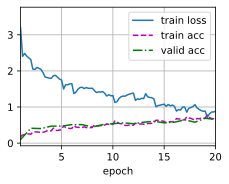

In [15]:
devices, num_epochs, lr, wd = d2l.try_all_gpus(), 20, 0.001, 5e-4
lr_period, lr_decay, net = 4, 0.9, get_net()
train(net, train_iter, valid_iter, num_epochs, lr, wd, devices, lr_period,
      lr_decay)

<!-- d2l:prose id=kaggle-cifar10-md-16 fw=all -->

## Classifying the Testing Set and Submitting Results on Kaggle

After obtaining a promising model with hyperparameters,
we use all the labeled data (including the validation set) to retrain the model and classify the testing set.

train loss 1.020, train acc 0.623
2684.7 examples/sec on [device(type='cuda', index=0)]


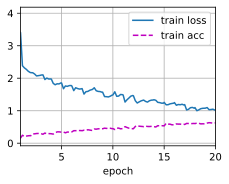

In [16]:
net, preds = get_net(), []
train(net, train_valid_iter, None, num_epochs, lr, wd, devices, lr_period,
      lr_decay)

for X, _ in test_iter:
    y_hat = net(X.to(devices[0]))
    preds.extend(y_hat.argmax(dim=1).type(torch.int32).cpu().numpy())
sorted_ids = list(range(1, len(test_ds) + 1))
sorted_ids.sort(key=lambda x: str(x))
df = pd.DataFrame({'id': sorted_ids, 'label': preds})
df['label'] = df['label'].apply(lambda x: train_valid_ds.classes[x])
df.to_csv('submission.csv', index=False)

<!-- d2l:prose id=kaggle-cifar10-md-17 fw=all -->

The above code
will generate a `submission.csv` file,
whose format
meets the requirement of the Kaggle competition.
The method
for submitting results to Kaggle
is similar to that in that section.

## Summary

* We can read datasets containing raw image files after organizing them into the required format.

<!-- d2l:prose id=kaggle-cifar10-md-18 fw=pytorch -->

* We can use convolutional neural networks and image augmentation in an image classification competition.

<!-- d2l:prose id=kaggle-cifar10-md-19 fw=all -->

## Exercises

1. `reorg_train_valid` puts $\max(\lfloor nr\rfloor,1)$ images of each class into the validation set. Compute the size of the validation set for the demo data (find $n$ from `labels`) and for the full dataset, both with `valid_ratio = 0.1`. Treat each validation image as an independent Bernoulli trial and compute the standard error of the validation accuracy at an accuracy of 50% for the demo split and of 90% for the full split. Taking twice the standard error of the difference of two independent estimates as the threshold, decide which of the differences of 0.5, 2, and 10 percentage points between two runs each split can distinguish from noise.
1. Before writing `submission.csv`, the code sorts the test ids as strings. Explain why by determining the order in which the test images are read from `train_valid_test/test/unknown`, and write down the first eight ids of the full test set of 300000 images in that order. If the ids were left in numeric order, what score would a classifier with perfect predictions receive, approximately, and why?
1. Use the complete CIFAR-10 dataset for this Kaggle competition. Set hyperparameters as `batch_size = 128`, `num_epochs = 100`, `lr = 0.1`, `lr_period = 50`, and `lr_decay = 0.1`.  See what accuracy and ranking you can achieve in this competition. Can you further improve them?
1. What accuracy can you get when not using image augmentation?
1. The ResNet-18 of this section starts with a $3\times 3$ convolution of stride 1 and has no max-pooling layer, whereas the ResNet-18 for ImageNet in that section starts with a $7\times 7$ convolution of stride 2 followed by $3\times 3$ max-pooling of stride 2. For $32\times 32$ inputs, compute the height and width of the feature maps after each of the four residual stages in both networks. Then replace the stem of the section's network by the ImageNet stem, train both networks on the full dataset with the same schedule, and compare their validation accuracies. Explain the result from the feature-map sizes.
1. Test-time augmentation averages the predictions for several transformed copies of each test image. For a network trained on the full dataset, average the softmax outputs for each validation image and its horizontal flip, and compare the resulting validation accuracy with that of the unflipped images alone. Using the standard error of the validation accuracy, state whether the difference exceeds the noise of the validation set, and explain why horizontal flips are a suitable transformation for this purpose while vertical flips are not.

<!-- d2l:prose id=kaggle-cifar10-md-20 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/1479)